# Stage 2: Human Pose Estimation

## Objectives

- Understand human pose estimation and keypoint representations.
- Run a pretrained pose-estimation model.
- Predict 17 human body keypoints.
- Understand normalized coordinates and confidence scores.
- Visualize predicted keypoints and the human skeleton.
- Apply pose estimation to a walking video.
- Save predictions for subsequent gait-analysis experiments.

## Dataset

Input video: `data/raw/sample_walking.mp4`

## Planned Model

MoveNet Lightning — single-person human pose estimation.

## Important Note

Stage 1 used hypothetical keypoints to practice coordinate mapping.
Stage 2 will use actual model predictions.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()

video_path = project_root / ".." / "data" / "raw" / "sample_walking.mp4"

print("Working directory:", project_root)
print("Video exists:", video_path.exists())

if video_path.exists():
    cap = cv2.VideoCapture(str(video_path))

    print("Video opened:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

    cap.release()

Working directory: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/notebooks
Video exists: True
Video opened: True
FPS: 29.97002997002997
Frame count: 405


In [2]:
from pathlib import Path
import sys

current_dir = Path.cwd().resolve()

project_root = next(
    (
        directory
        for directory in [current_dir, *current_dir.parents]
        if (directory / "pyproject.toml").exists()
    ),
    None,
)

if project_root is None:
    raise RuntimeError("Could not locate the project root.")

video_path = project_root / "data" / "raw" / "sample_walking.mp4"

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Project root:", project_root)
print("Video exists:", video_path.exists())

Python executable: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/.venv/bin/python
Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Project root: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab
Video exists: True


In [3]:
from ai_edge_litert.interpreter import Interpreter

model_path = project_root / "models" / "movenet_lightning.tflite"

if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path}")

interpreter = Interpreter(
    model_path=str(model_path),
    num_threads=4,
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Model loaded successfully!")
print("\nInput details:")
for item in input_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

print("\nOutput details:")
for item in output_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

Model loaded successfully!

Input details:
{'shape': [1, 192, 192, 3], 'dtype': "<class 'numpy.uint8'>", 'name': 'serving_default_input:0'}

Output details:
{'shape': [1, 1, 17, 3], 'dtype': "<class 'numpy.float32'>", 'name': 'StatefulPartitionedCall:0'}


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [4]:
print("INPUT DETAILS")
for item in input_details:
    print(item)

print("\nOUTPUT DETAILS")
for item in output_details:
    print(item)

INPUT DETAILS
{'name': 'serving_default_input:0', 'index': 0, 'shape': array([  1, 192, 192,   3], dtype=int32), 'shape_signature': array([  1, 192, 192,   3], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}

OUTPUT DETAILS
{'name': 'StatefulPartitionedCall:0', 'index': 316, 'shape': array([ 1,  1, 17,  3], dtype=int32), 'shape_signature': array([ 1,  1, 17,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}


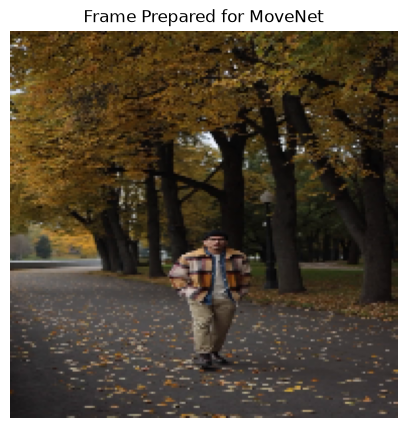

Original frame: (1920, 1080, 3)
Model input image: (192, 192, 3)
Expected model input shape: [  1 192 192   3]


In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError(f"Failed to open video: {video_path}")

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Failed to read a frame from the video.")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


input_shape = input_details[0]["shape"]
input_height, input_width = int(input_shape[1]), int(input_shape[2])

resized_frame = cv2.resize(
    frame_rgb, (input_width, input_height)
)

plt.figure(figsize=(5, 7))
plt.imshow(resized_frame)
plt.title("Frame Prepared for MoveNet")
plt.axis("off")
plt.show()

print("Original frame:", frame.shape)
print("Model input image:", resized_frame.shape)
print("Expected model input shape:", input_shape)

In [6]:
input_dtype = input_details[0]["dtype"]

# Add a batch dimension: (H, W, C) -> (1, H, W, C)
model_input = np.expand_dims(resized_frame, axis=0)

if input_dtype == np.uint8:
    model_input = model_input.astype(np.uint8)
elif input_dtype == np.float32:
    model_input = model_input.astype(np.float32)
else:
    raise TypeError(f"Unexpected model input dtype: {input_dtype}")

interpreter.set_tensor(
    input_details[0]["index"],
    model_input,
)

interpreter.invoke()

raw_output = interpreter.get_tensor(
    output_details[0]["index"]
)

keypoints = np.squeeze(raw_output)

print("Raw output shape:", raw_output.shape)
print("Keypoints shape:", keypoints.shape)

if keypoints.shape != (17, 3):
    raise ValueError(
        f"Expected 17 keypoints with 3 values each, "
        f"but received {keypoints.shape}"
    )

print("\nFirst five keypoints:")
for index, (y, x, score) in enumerate(keypoints[:5]):
    print(
        f"Keypoint {index}: "
        f"y={y:.4f}, x={x:.4f}, confidence={score:.4f}"
    )

Raw output shape: (1, 1, 17, 3)
Keypoints shape: (17, 3)

First five keypoints:
Keypoint 0: y=0.5516, x=0.5345, confidence=0.3566
Keypoint 1: y=0.5437, x=0.5424, confidence=0.4331
Keypoint 2: y=0.5404, x=0.5271, confidence=0.4871
Keypoint 3: y=0.5394, x=0.5517, confidence=0.3587
Keypoint 4: y=0.5374, x=0.5129, confidence=0.5249


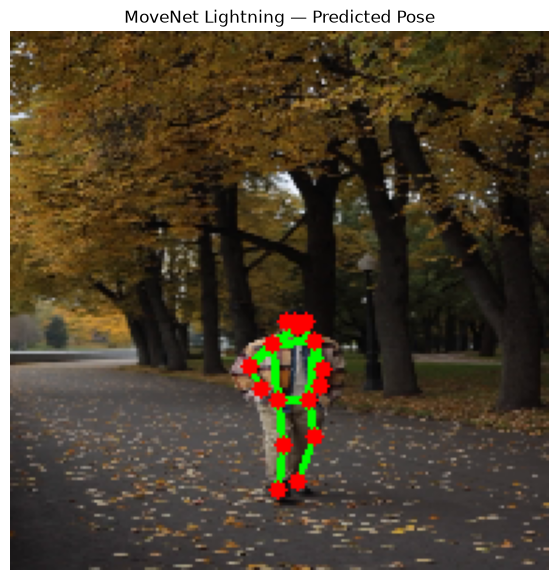

In [7]:
# MoveNet keypoint indices
KEYPOINT_NAMES = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle",
]

# Pairs of keypoints to connect
SKELETON_EDGES = [
    (0, 1), (0, 2),
    (1, 3), (2, 4),
    (0, 5), (0, 6),
    (5, 7), (7, 9),
    (6, 8), (8, 10),
    (5, 6),
    (5, 11), (6, 12),
    (11, 12),
    (11, 13), (13, 15),
    (12, 14), (14, 16),
]

confidence_threshold = 0.2

# Draw on the resized RGB image used for inference.
annotated_image = resized_frame.copy()

image_height, image_width = annotated_image.shape[:2]

# Convert normalized coordinates into pixel coordinates.
keypoint_pixels = []

for y, x, score in keypoints:
    x_pixel = int(x * image_width)
    y_pixel = int(y * image_height)

    keypoint_pixels.append((x_pixel, y_pixel, float(score)))

# Draw skeleton connections.
for start_idx, end_idx in SKELETON_EDGES:
    x1, y1, score1 = keypoint_pixels[start_idx]
    x2, y2, score2 = keypoint_pixels[end_idx]

    if (
        score1 >= confidence_threshold
        and score2 >= confidence_threshold
    ):
        cv2.line(
            annotated_image,
            (x1, y1),
            (x2, y2),
            color=(0, 255, 0),
            thickness=2,
        )

# Draw keypoints.
for idx, (x_pixel, y_pixel, score) in enumerate(keypoint_pixels):
    if score >= confidence_threshold:
        cv2.circle(
            annotated_image,
            (x_pixel, y_pixel),
            radius=3,
            color=(255, 0, 0),
            thickness=-1,
        )

plt.figure(figsize=(7, 7))
plt.imshow(annotated_image)
plt.title("MoveNet Lightning — Predicted Pose")
plt.axis("off")
plt.show()